In [2]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from typing import Dict, Tuple
import h5py
from scipy.interpolate import interp1d
import imageio.v2 as imageio
from tqdm import tqdm
from skimage.transform import rotate
import scipy.fftpack as fft         
import torch
from deepinv.datasets import LidcIdriSliceDataset
import torchvision.transforms as transforms
import os

def normalize(x):
    x = x.astype(np.float32)
    normalized = x / np.max(x)
    return np.clip(normalized.astype(np.float32), 0, 1)

def radon(image, steps):        
    # Build the Radon Transform using 'steps' projections of 'image'. 
    projections = []        ## Accumulate projections in a list.
    dTheta = -180.0 / steps ## Angle increment for rotations.
    for i in range(steps):
        projections.append(rotate(image, i*dTheta).sum(axis=0))
    
    return np.vstack(projections) # Return the projections as a sinogram

def fft_translate(projs):
    # Build 1-d FFTs of an array of projections, each projection 1 row of the array.
    return fft.rfft(projs, axis=1)

def ramp_filter(ffts):
    # Ramp filter a 2-d array of 1-d FFTs (1-d FFTs along the rows).
    ramp = np.floor(np.arange(0.5, ffts.shape[1]//2 + 0.1, 0.5))
    return ffts * ramp

def inverse_fft_translate(operator):
    # Return to the spatial domain using inverse Fourier Transform
    return fft.irfft(operator, axis=1)

def back_project(operator):
    laminogram = np.zeros((operator.shape[1], operator.shape[1]))
    dTheta = 180.0 / operator.shape[0]
    for i in range(operator.shape[0]):
        temp = np.tile(operator[i], (operator.shape[1], 1))
        temp = rotate(temp, dTheta*i)
        laminogram += temp
    return laminogram

/home/ty392/.conda/envs/qutcc/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.1
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


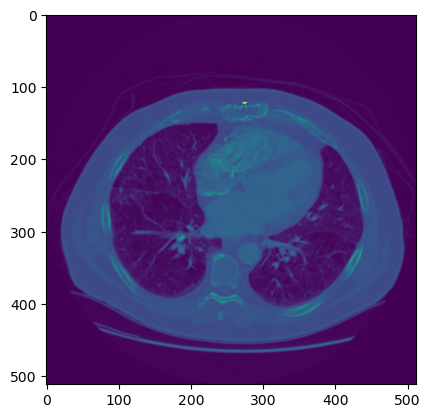

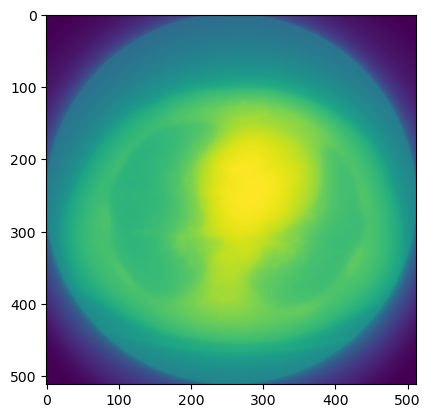

In [5]:
test = plt.imread("/share/monakhova/Cassandra_data/UQNet_proj/CT_Scan/manifest-1600709154662/new_clean/9275.png")
plt.imshow(test)
plt.show()
test = plt.imread("/share/monakhova/Cassandra_data/UQNet_proj/CT_Scan/manifest-1600709154662/new_noisy/9275.png")
plt.imshow(test)
plt.show()

Starting...
length of dataset: 20032


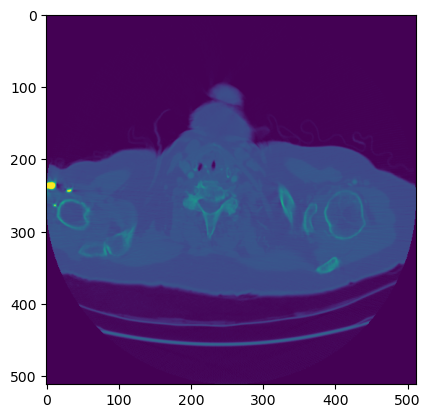

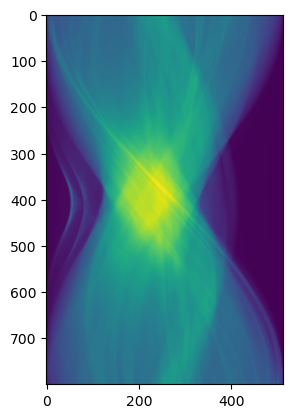

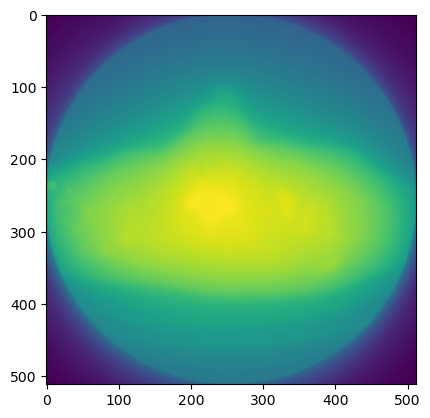

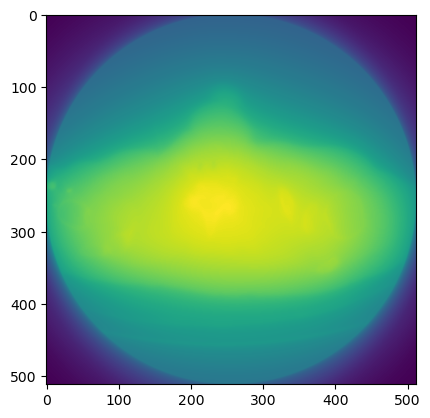

noisy image shape =  (512, 512)


In [4]:

print("Starting...")
preprocessing = transforms.Compose([
    transforms.Lambda(lambda x: normalize(x))  # Direct numpy normalization
])
root = "/share/monakhova/Cassandra_data/UQNet_proj/CT_Scan/manifest-1600709154662"

gt_folder = "/share/monakhova/Cassandra_data/UQNet_proj/CT_Scan/manifest-1600709154662/clean"
noisy_folder = "/share/monakhova/Cassandra_data/UQNet_proj/CT_Scan/manifest-1600709154662/noisy"

dataset = LidcIdriSliceDataset(
    root=root,
    hounsfield_units=False,  # Raw pixel values, not HU
    transform=preprocessing  # This now returns (degraded, gt) pairs
)
print(f"length of dataset: {len(dataset)}")

for im in range(1):
    clean_image = dataset[im]
    plt.imshow(clean_image)
    plt.show()
    radon_transform = radon(clean_image, 800)
    plt.imshow(radon_transform)
    plt.show()
    noisy_image = back_project(radon_transform)
    plt.imshow(noisy_image)
    plt.show()
    noisy_image = normalize(noisy_image)
    plt.imshow(noisy_image)
    plt.show()
    print("noisy image shape = ", noisy_image.shape)
    #clean_filename = os.path.join(gt_folder, f"{im:04d}.png")
    #noisy_filename = os.path.join(noisy_folder, f"{im:04d}.png")
    #cv2.imwrite(clean_filename, clean_image)
    #cv2.imwrite(noisy_filename, noisy_image)
        
    #print(f"Saved images {im:04d}")
    
